# Car Price Prediction System Using Machine Learning

## Machine Learning 2 Assignment

### Objective
To develop a machine learning system that predicts the selling price of a used car based on its characteristics such as present price, manufacturing year, kilometers driven, fuel type, seller type, transmission type, and number of previous owners.

## 1. Introduction

Car price prediction is an important application of machine learning in the automobile market. The price of a used car depends on several factors such as its present price, manufacturing year, kilometers driven, fuel type, transmission type, seller type, and number of previous owners.

The objective of this project is to develop a supervised machine learning regression model that can predict the selling price of a used car. The CarDekho vehicle dataset containing 301 records and 9 attributes is used for this study. Data preprocessing, exploratory data analysis, feature engineering, and machine learning techniques are applied to develop the prediction system.

A Random Forest Regressor is used as the primary prediction algorithm, and its performance is evaluated using MAE, MSE, RMSE, and R² Score.

## 2. Methodology

The following steps were followed to develop the Car Price Prediction System:

1. Dataset collection
2. Data loading using Pandas
3. Data cleaning and missing-value analysis
4. Exploratory Data Analysis
5. Feature engineering
6. Categorical variable encoding
7. Feature and target separation
8. Train-test split
9. Random Forest Regression model training
10. Price prediction
11. Model evaluation
12. Feature importance analysis

## 3. Dataset Description

The dataset contains 301 car records and 9 attributes.

| Attribute | Description |
|---|---|
| Car_Name | Name of the car |
| Year | Manufacturing year |
| Selling_Price | Selling price of the car |
| Present_Price | Present/current price |
| Kms_Driven | Kilometers driven |
| Fuel_Type | Type of fuel |
| Seller_Type | Type of seller |
| Transmission | Transmission type |
| Owner | Number of previous owners |

The target variable is `Selling_Price`.

## 4. Model Performance

The Random Forest Regressor was trained using 80% of the dataset and evaluated using the remaining 20%.

### Evaluation Metrics

| Metric | Result |
|---|---:|
| MAE | 0.6387 |
| MSE | 0.9216 |
| RMSE | 0.9599 |
| R² Score | 0.9600 |

The Random Forest model achieved an R² Score of approximately 0.96, indicating that the model explains approximately 96% of the variation in the test-set selling prices.

## 5. Conclusion

The Car Price Prediction System was successfully developed using supervised machine learning. The dataset was cleaned and analyzed through exploratory data analysis, followed by feature engineering and categorical encoding.

A Random Forest Regressor was trained to predict the selling price of used cars. The model achieved an R² Score of approximately 0.96, demonstrating strong predictive performance on the test dataset. The feature importance analysis showed that Present_Price was the most influential feature for predicting Selling_Price.

The developed system can be used to estimate the expected selling price of a used car based on its characteristics.

## 6. Future Scope

The system can be further improved by:

- Using larger and more diverse car datasets.
- Comparing multiple machine learning algorithms.
- Applying hyperparameter optimization.
- Developing a graphical user interface.
- Deploying the prediction system as a web application.
- Adding real-time automobile market data.

## 7. Technologies Used

- Python
- Jupyter Notebook
- Pandas
- NumPy
- Matplotlib
- Seaborn
- Scikit-learn
- Random Forest Regression

In [25]:
import pandas as pd
import numpy as np

# Load the dataset
dataset = pd.read_csv("CarDekho_Dataset.csv")

# Display dataset shape
print("Dataset Shape:", dataset.shape)

# Display first 5 records
dataset.head()

Dataset Shape: (301, 9)


,Car_Name,Year,Selling_Price,Present_Price,Kms_Driven,Fuel_Type,Seller_Type,Transmission,Owner
0,ritz,2014,3.35,5.59,27000,Petrol,Dealer,Manual,0
1,sx4,2013,4.75,9.54,43000,Diesel,Dealer,Manual,0
2,ciaz,2017,7.25,9.85,6900,Petrol,Dealer,Manual,0
3,wagon r,2011,2.85,4.15,5200,Petrol,Dealer,Manual,0
4,swift,2014,4.60,6.87,42450,Diesel,Dealer,Manual,0


In [2]:
dataset.isnull().sum()

Car_Name         0
Year             0
Selling_Price    0
Present_Price    0
Kms_Driven       0
Fuel_Type        0
Seller_Type      0
Transmission     0
Owner            0
dtype: int64

In [3]:
dataset.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 301 entries, 0 to 300
Data columns (total 9 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Car_Name       301 non-null    object 
 1   Year           301 non-null    int64  
 2   Selling_Price  301 non-null    float64
 3   Present_Price  301 non-null    float64
 4   Kms_Driven     301 non-null    int64  
 5   Fuel_Type      301 non-null    object 
 6   Seller_Type    301 non-null    object 
 7   Transmission   301 non-null    object 
 8   Owner          301 non-null    int64  
dtypes: float64(2), int64(3), object(4)
memory usage: 21.3+ KB


In [4]:
dataset.describe()

,Year,Selling_Price,Present_Price,Kms_Driven,Owner
count,301.000000,301.000000,301.000000,301.000000,301.000000
mean,2013.627907,4.661296,7.628472,36947.205980,0.043189
std,2.891554,5.082812,8.644115,38886.883882,0.247915
min,2003.000000,0.100000,0.320000,500.000000,0.000000
25%,2012.000000,0.900000,1.200000,15000.000000,0.000000
50%,2014.000000,3.600000,6.400000,32000.000000,0.000000
75%,2016.000000,6.000000,9.900000,48767.000000,0.000000
max,2018.000000,35.000000,92.600000,500000.000000,3.000000


In [5]:
print("Fuel Types:")
print(dataset["Fuel_Type"].value_counts())

print("\nSeller Types:")
print(dataset["Seller_Type"].value_counts())

print("\nTransmission Types:")
print(dataset["Transmission"].value_counts())

print("\nOwner Distribution:")
print(dataset["Owner"].value_counts())

Fuel Types:
Fuel_Type
Petrol    239
Diesel     60
CNG         2
Name: count, dtype: int64

Seller Types:
Seller_Type
Dealer        195
Individual    106
Name: count, dtype: int64

Transmission Types:
Transmission
Manual       261
Automatic     40
Name: count, dtype: int64

Owner Distribution:
Owner
0    290
1     10
3      1
Name: count, dtype: int64


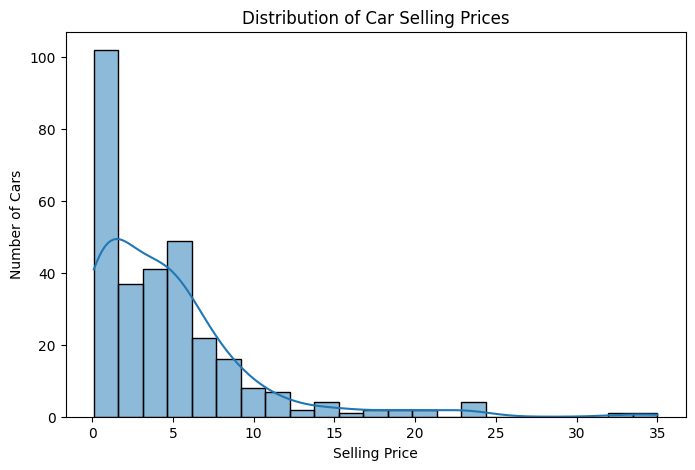

In [6]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(8, 5))
sns.histplot(dataset["Selling_Price"], kde=True)
plt.title("Distribution of Car Selling Prices")
plt.xlabel("Selling Price")
plt.ylabel("Number of Cars")
plt.show()

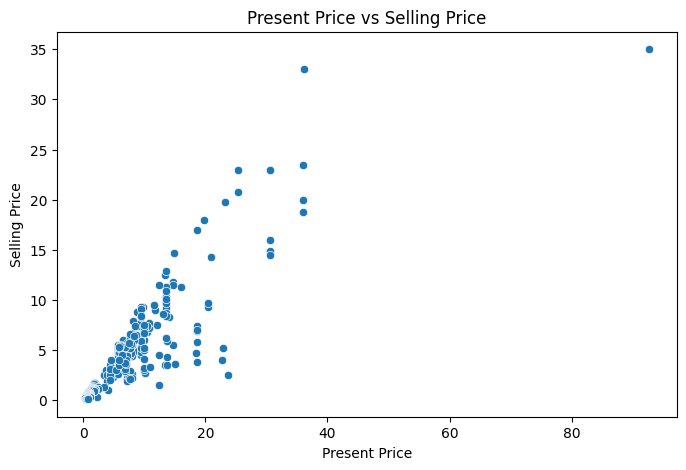

In [7]:
plt.figure(figsize=(8, 5))

sns.scatterplot(
    data=dataset,
    x="Present_Price",
    y="Selling_Price"
)

plt.title("Present Price vs Selling Price")
plt.xlabel("Present Price")
plt.ylabel("Selling Price")
plt.show()

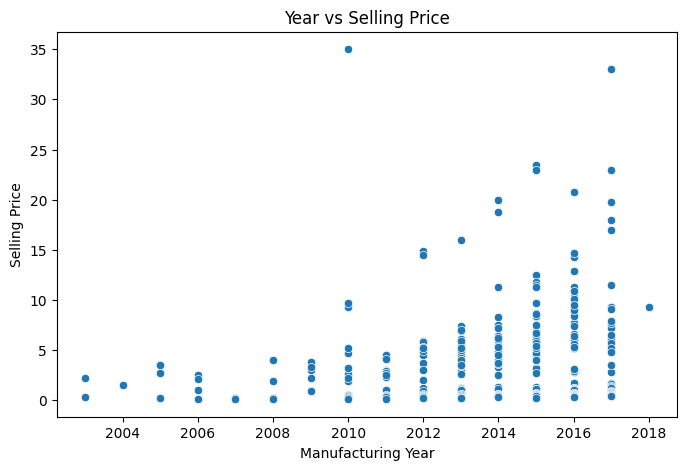

In [8]:
plt.figure(figsize=(8, 5))

sns.scatterplot(
    data=dataset,
    x="Year",
    y="Selling_Price"
)

plt.title("Year vs Selling Price")
plt.xlabel("Manufacturing Year")
plt.ylabel("Selling Price")
plt.show()

In [9]:
correlation = dataset[
    ["Year", "Selling_Price", "Present_Price", "Kms_Driven", "Owner"]
].corr()

print(correlation)

                   Year  Selling_Price  Present_Price  Kms_Driven     Owner
Year           1.000000       0.236141      -0.047584   -0.524342 -0.182104
Selling_Price  0.236141       1.000000       0.878983    0.029187 -0.088344
Present_Price -0.047584       0.878983       1.000000    0.203647  0.008057
Kms_Driven    -0.524342       0.029187       0.203647    1.000000  0.089216
Owner         -0.182104      -0.088344       0.008057    0.089216  1.000000


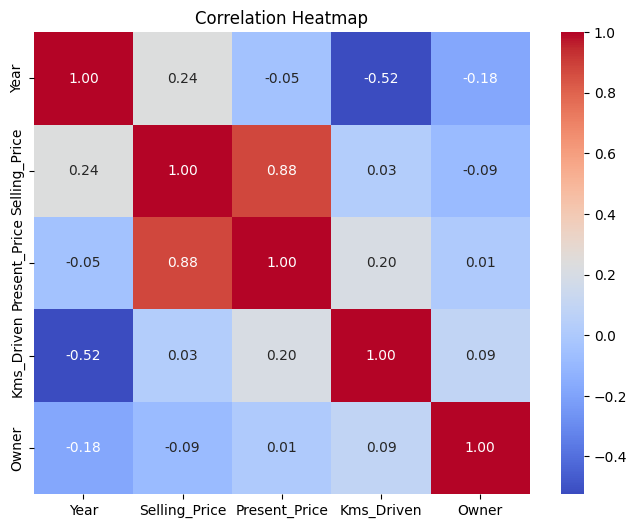

In [10]:
plt.figure(figsize=(8, 6))

sns.heatmap(
    correlation,
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Correlation Heatmap")
plt.show()

In [11]:
# Create a copy of the dataset
final_dataset = dataset.copy()

# Calculate car age
final_dataset["no_of_year"] = 2026 - final_dataset["Year"]

# Remove columns that are not required
final_dataset.drop(["Car_Name", "Year"], axis=1, inplace=True)

# Convert categorical variables into numerical variables
final_dataset = pd.get_dummies(
    final_dataset,
    columns=["Fuel_Type", "Seller_Type", "Transmission"],
    drop_first=True
)

# Display the processed dataset
final_dataset.head()

,Selling_Price,Present_Price,Kms_Driven,Owner,no_of_year,Fuel_Type_Diesel,Fuel_Type_Petrol,Seller_Type_Individual,Transmission_Manual
0,3.35,5.59,27000,0,12,False,True,False,True
1,4.75,9.54,43000,0,13,True,False,False,True
2,7.25,9.85,6900,0,9,False,True,False,True
3,2.85,4.15,5200,0,15,False,True,False,True
4,4.60,6.87,42450,0,12,True,False,False,True


In [12]:
X = final_dataset.drop("Selling_Price", axis=1)
y = final_dataset["Selling_Price"]

print("Features (X) shape:", X.shape)
print("Target (y) shape:", y.shape)

Features (X) shape: (301, 8)
Target (y) shape: (301,)


In [13]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42
)

print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

Training data: (240, 8)
Testing data: (61, 8)


In [14]:
from sklearn.ensemble import RandomForestRegressor

# Create the Random Forest model
rf_model = RandomForestRegressor(
    n_estimators=100,
    random_state=42
)

# Train the model
rf_model.fit(X_train, y_train)

print("Random Forest model trained successfully!")

Random Forest model trained successfully!


In [15]:
y_pred = rf_model.predict(X_test)

print("First 10 Predictions:")
print(y_pred[:10])

First 10 Predictions:
[ 0.4428 10.987   4.872   0.2168  7.8305  6.181   1.107   0.5906  0.4689
  6.902 ]


In [16]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

mae = mean_absolute_error(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_pred)

print("Model Evaluation:")
print("------------------")
print("MAE  :", mae)
print("MSE  :", mse)
print("RMSE :", rmse)
print("R² Score:", r2)

Model Evaluation:
------------------
MAE  : 0.63872131147541
MSE  : 0.9215642422950816
RMSE : 0.9599813760147025
R² Score: 0.9599938850484411


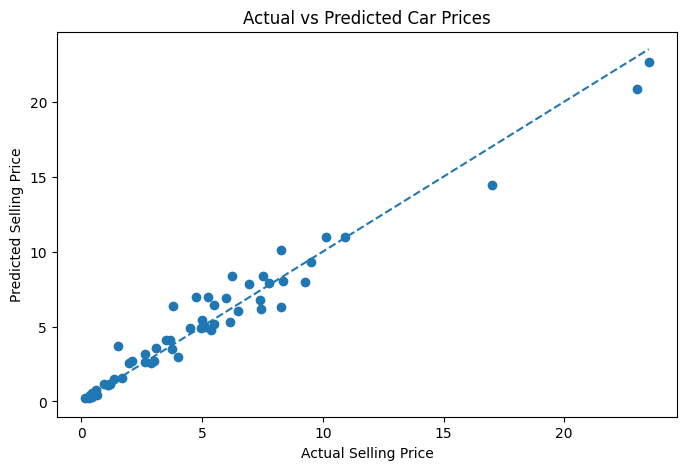

In [17]:
plt.figure(figsize=(8, 5))

plt.scatter(y_test, y_pred)

plt.plot(
    [y_test.min(), y_test.max()],
    [y_test.min(), y_test.max()],
    linestyle="--"
)

plt.xlabel("Actual Selling Price")
plt.ylabel("Predicted Selling Price")
plt.title("Actual vs Predicted Car Prices")

plt.show()

In [18]:
# Get feature importance
feature_importance = pd.Series(
    rf_model.feature_importances_,
    index=X.columns
).sort_values(ascending=False)

print(feature_importance)

Present_Price             0.882877
no_of_year                0.060123
Kms_Driven                0.036249
Transmission_Manual       0.010395
Fuel_Type_Petrol          0.004028
Fuel_Type_Diesel          0.002894
Seller_Type_Individual    0.002083
Owner                     0.001351
dtype: float64


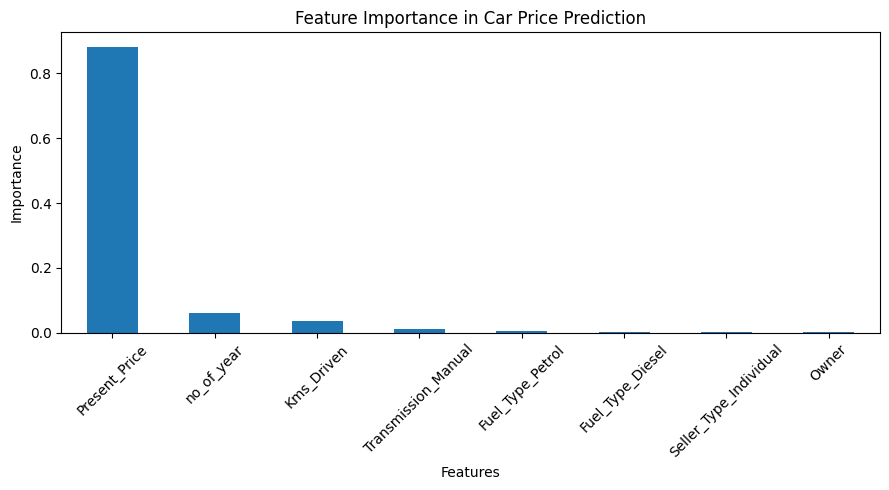

In [19]:
plt.figure(figsize=(9, 5))

feature_importance.plot(kind="bar")

plt.title("Feature Importance in Car Price Prediction")
plt.xlabel("Features")
plt.ylabel("Importance")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [21]:
def predict_car_price(year, present_price, kms_driven,
                      fuel_type, seller_type, transmission, owner):

    # Calculate car age
    no_of_year = 2026 - year

    # Create input with all model features initialized to 0
    input_data = pd.DataFrame(0, index=[0], columns=X.columns)

    # Set numerical values
    input_data["Present_Price"] = present_price
    input_data["Kms_Driven"] = kms_driven
    input_data["Owner"] = owner
    input_data["no_of_year"] = no_of_year

    # Set categorical encoded values
    if fuel_type == "Petrol":
        input_data["Fuel_Type_Petrol"] = 1
    elif fuel_type == "Diesel":
        input_data["Fuel_Type_Diesel"] = 1

    if seller_type == "Individual":
        input_data["Seller_Type_Individual"] = 1

    if transmission == "Manual":
        input_data["Transmission_Manual"] = 1

    # Predict price
    predicted_price = rf_model.predict(input_data)[0]

    return predicted_price

In [22]:
predicted_price = predict_car_price(
    year=2018,
    present_price=8.5,
    kms_driven=25000,
    fuel_type="Petrol",
    seller_type="Dealer",
    transmission="Manual",
    owner=0
)

print("Predicted Car Selling Price: ₹", round(predicted_price, 2), "Lakhs")

Predicted Car Selling Price: ₹ 6.83 Lakhs


In [23]:
predicted_price = predict_car_price(
    year=2015,
    present_price=5.5,
    kms_driven=40000,
    fuel_type="Diesel",
    seller_type="Individual",
    transmission="Manual",
    owner=1
)

print("Predicted Car Selling Price: ₹", round(predicted_price, 2), "Lakhs")

Predicted Car Selling Price: ₹ 3.36 Lakhs
